In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Positional Bias — Moondream2 across Kvasir-SEG, ISIC 2018, and LGG (50 images each)

Runs **Moondream2** (`vikhyatk/moondream2`) zero-shot on 50 sampled images x 5 positional prompts
(P0-P4) from `position_bias_research_plan.md` per dataset, and scores its answers against the ground
truth already computed in each dataset's `manifest_<name>.csv`.

**Scope of this run**
- Datasets: Kvasir-SEG (colon polyps), ISIC 2018 (skin lesions), LGG Segmentation (brain tumors) —
  50 images x 5 prompts = 250 rows each
- Model: Moondream2, zero-shot, no fine-tuning, loaded **once** and reused across all datasets
- **Deviation from the plan's model table**: the plan lists Moondream2 in the pixel-mask tier via its
  hosted `/segment` endpoint. The local, offline-loadable weights used here (`transformers`,
  `trust_remote_code=True`) only expose `detect()` (bounding box) and `point()` (single x, y) — there is
  no local segmentation method. We therefore record **both** `detect()` and `point()` outputs per row.
- Moondream2's `detect()` sometimes returns a box spanning (almost) the whole image when it can't
  localize the target; that is treated as "no detection" (NaN), not a real position — see the scoring
  section below.

**What this notebook produces, per dataset `<name>` in `{kvasir, isic, lgg}`**
- `results_<name>/<name>_moondream2_results.csv` — the manifest plus new prediction/scoring columns
  appended after `prompt_text`
- `results_<name>/visualizations/<sample_id>.png` — one figure per image, all 5 prompts side by side,
  showing ground truth (red) vs. Moondream2's `detect()` box (blue) and `point()` (green)
- `results_<name>/<name>_moondream2_summary_by_prompt.csv` — aggregated wrong-side rate / distance by prompt
- Inline plots in this notebook for a handful of examples plus the summary charts, per dataset

## How to run this in Google Colab

1. Upload the entire `run_colab/` folder (this notebook + `data/kvasir/`, `data/isic/`, `data/lgg/`)
   into your Colab session, or mount Google Drive and place it there (this notebook mounts Drive at
   `/content/drive` and expects the folder at `/content/drive/MyDrive/run_colab`).
2. `Runtime > Change runtime type > T4 GPU` (Moondream2 is 2B params; CPU works but is much slower).
3. Run all cells top to bottom. **No Hugging Face token is needed** — `vikhyatk/moondream2` is a public,
   non-gated model.
4. Inference over 250 rows (2 model calls each) takes roughly 10-20 minutes per dataset on a T4 --
   about 30-60 minutes total for all 3 datasets.
5. Just run every cell top to bottom, in order, on a fresh runtime -- there is no manual setup step

   and nothing needs to have been run before; the final loop cell processes Kvasir-SEG, ISIC 2018,   and LGG one after another using the functions defined earlier in the notebook.

In [5]:
%pip install -q "transformers==4.56.1" "pyvips-binary==8.16.0" "pyvips==2.2.3" "accelerate==1.10.1" pillow pandas matplotlib tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 94.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 111.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 47.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [6]:
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    ROOT = Path("/content/drive/MyDrive/run_colab")
    if not ROOT.exists():
        raise FileNotFoundError(
            "Upload the whole 'run_colab' folder into /content (e.g. drag it into the Colab file "
            "browser on the left, or mount Drive and copy it there) before running this cell."
        )
else:
    ROOT = Path.cwd()
    if ROOT.name != "run_colab":
        candidate = ROOT / "run_colab"
        ROOT = candidate if candidate.exists() else ROOT

print(f"ROOT = {ROOT}")


def get_dataset_paths(dataset_name, results_folder):
    """Return (data_dir, out_dir, vis_dir) for one dataset, creating the output dirs."""
    data_dir = ROOT / "data" / dataset_name
    out_dir = ROOT / results_folder
    vis_dir = out_dir / "visualizations"
    out_dir.mkdir(parents=True, exist_ok=True)
    vis_dir.mkdir(parents=True, exist_ok=True)
    return data_dir, out_dir, vis_dir

ROOT = /content/drive/MyDrive/run_colab


In [7]:
import pandas as pd


def load_manifest(dataset_name, data_dir):
    manifest = pd.read_csv(data_dir / f"manifest_{dataset_name}.csv")
    assert len(manifest) == 250, f"{dataset_name}: expected 250 rows (50 images x 5 prompts), got {len(manifest)}"
    assert manifest["sample_id"].nunique() == 50, f"{dataset_name}: expected 50 unique images"
    print(f"[ok] {dataset_name}: loaded manifest with {len(manifest)} rows, {manifest['sample_id'].nunique()} images")
    return manifest

In [8]:
import torch
from transformers import AutoModelForCausalLM

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("[warn] No GPU detected. Moondream2 (2B params) will be slow on CPU. "
          "In Colab: Runtime > Change runtime type > T4 GPU.")

MODEL_REVISION = "2025-06-21"

model = AutoModelForCausalLM.from_pretrained(
    "vikhyatk/moondream2",
    revision=MODEL_REVISION,
    trust_remote_code=True,
    device_map={"": DEVICE},
)
model.eval()
print(f"[ok] loaded moondream2 (revision={MODEL_REVISION}) on {DEVICE}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/277 [00:00<?, ?B/s]

hf_moondream.py: 0.00B [00:00, ?B/s]

config.py: 0.00B [00:00, ?B/s]

text.py: 0.00B [00:00, ?B/s]

...

utils.py: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.85G [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

generation_config.json:   0%|          | 0.00/69.0 [00:00<?, ?B/s]

[ok] loaded moondream2 (revision=2025-06-21) on cuda


## Run inference

For each of the 250 (image, prompt) rows, we call both `model.detect(image, prompt_text)` and
`model.point(image, prompt_text)`, exactly as documented on the model card — the same `prompt_text`
from the manifest is sent unmodified, so the model sees the full "Please locate the polyp on the
right side of this image." sentence, not a shortened keyword.

Moondream2 returns box/point coordinates normalized to `[0, 1]` relative to image width/height; we
convert those to pixel coordinates immediately so everything downstream matches the manifest's
pixel-space ground truth (`gt_centroid_x/y`, `gt_bbox_*`).

In [9]:
import numpy as np


def _to_pixel_bbox(obj, width, height):
    return obj["x_min"] * width, obj["y_min"] * height, obj["x_max"] * width, obj["y_max"] * height


def _to_pixel_point(pt, width, height):
    return pt["x"] * width, pt["y"] * height


def run_detect(model, image, text):
    """Return (best_bbox_in_pixels_or_None, raw_objects_list)."""
    result = model.detect(image, text)
    objects = result.get("objects", [])
    if not objects:
        return None, objects
    w, h = image.size
    return _to_pixel_bbox(objects[0], w, h), objects


def run_point(model, image, text):
    """Return (best_point_in_pixels_or_None, raw_points_list)."""
    result = model.point(image, text)
    points = result.get("points", [])
    if not points:
        return None, points
    w, h = image.size
    return _to_pixel_point(points[0], w, h), points

In [10]:
import json

from PIL import Image
from tqdm.auto import tqdm


def run_moondream_inference(model, manifest_df, data_dir, desc="Moondream2 inference"):
    """Call detect() and point() for every row; returns a new df with md_detect_*/md_point_* columns."""
    df = manifest_df.copy()
    detect_xmin, detect_ymin, detect_xmax, detect_ymax, detect_raw = [], [], [], [], []
    point_x, point_y, point_raw = [], [], []

    for _, row in tqdm(df.iterrows(), total=len(df), desc=desc):
        image = Image.open(data_dir / row["image_path"]).convert("RGB")

        try:
            bbox, raw_d = run_detect(model, image, row["prompt_text"])
        except Exception as e:  # keep the run alive if one row errors out
            bbox, raw_d = None, {"error": str(e)}
        try:
            pt, raw_p = run_point(model, image, row["prompt_text"])
        except Exception as e:
            pt, raw_p = None, {"error": str(e)}

        if bbox is not None:
            detect_xmin.append(bbox[0]); detect_ymin.append(bbox[1])
            detect_xmax.append(bbox[2]); detect_ymax.append(bbox[3])
        else:
            detect_xmin.append(np.nan); detect_ymin.append(np.nan)
            detect_xmax.append(np.nan); detect_ymax.append(np.nan)
        detect_raw.append(json.dumps(raw_d))

        if pt is not None:
            point_x.append(pt[0]); point_y.append(pt[1])
        else:
            point_x.append(np.nan); point_y.append(np.nan)
        point_raw.append(json.dumps(raw_p))

    df["md_detect_xmin"] = detect_xmin
    df["md_detect_ymin"] = detect_ymin
    df["md_detect_xmax"] = detect_xmax
    df["md_detect_ymax"] = detect_ymax
    df["md_detect_raw"] = detect_raw
    df["md_point_x"] = point_x
    df["md_point_y"] = point_y
    df["md_point_raw"] = point_raw

    print(f"[ok] ran inference on {len(df)} rows")
    return df

## Score predictions against ground truth

Adds, per row: predicted side (left/right, upper/lower), whether that matches the *prompted* direction
(RQ1/RQ3), whether the prompted direction actually matched this image's true ground-truth side (needed
to split rows for RQ2 vs RQ3), IoU of the `detect()` box against `gt_bbox_*`, normalized distance to
`gt_centroid_x/y`, and the shift from this same image's own P0 answer (RQ1's "did it move at all?").

In [11]:
from PIL import Image as PILImage


def side_lr(x, width):
    return "left" if x < width / 2 else "right"


def side_ud(y, height):
    return "upper" if y < height / 2 else "lower"


PROMPT_AXIS = {
    "P0": (None, None),
    "P1": ("lr", "left"),
    "P2": ("lr", "right"),
    "P3": ("ud", "upper"),
    "P4": ("ud", "lower"),
}


def correct_side(row, side_lr_col, side_ud_col):
    # Returns 1.0/0.0 (not bool) and NaN (not None) so the column stays numeric for mean(numeric_only=True).
    if row["prompted_axis"] == "lr" and row[side_lr_col] is not None:
        return float(row[side_lr_col] == row["prompted_direction"])
    if row["prompted_axis"] == "ud" and row[side_ud_col] is not None:
        return float(row[side_ud_col] == row["prompted_direction"])
    return np.nan  # P0 has no prompted direction to compare against


def prompt_matches_gt(row):
    """Model-independent: does the prompted direction match this image's real ground truth side?"""
    if row["prompted_axis"] == "lr":
        return row["prompted_direction"] == row["gt_side_lr"]
    if row["prompted_axis"] == "ud":
        return row["prompted_direction"] == row["gt_side_ud"]
    return None


def iou(row):
    if pd.isna(row["md_detect_xmin"]):
        return np.nan
    xa1, ya1, xa2, ya2 = row["md_detect_xmin"], row["md_detect_ymin"], row["md_detect_xmax"], row["md_detect_ymax"]
    xb1, yb1, xb2, yb2 = row["gt_bbox_xmin"], row["gt_bbox_ymin"], row["gt_bbox_xmax"], row["gt_bbox_ymax"]
    ix1, iy1 = max(xa1, xb1), max(ya1, yb1)
    ix2, iy2 = min(xa2, xb2), min(ya2, yb2)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, xa2 - xa1) * max(0, ya2 - ya1)
    area_b = max(0, xb2 - xb1) * max(0, yb2 - yb1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else np.nan


def norm_dist(px, py, row):
    if pd.isna(px):
        return np.nan
    diag = np.hypot(row["img_width"], row["img_height"])
    return np.hypot(px - row["gt_centroid_x"], py - row["gt_centroid_y"]) / diag


def no_shift(row, shift_col):
    """1.0 if the answer moved less than 5% of the image diagonal from its own P0 answer, else 0.0, NaN if not applicable."""
    if row["prompt_id"] == "P0" or pd.isna(row[shift_col]):
        return np.nan
    diag = np.hypot(row["img_width"], row["img_height"])
    return float(row[shift_col] < 0.05 * diag)


def score_predictions(df, data_dir):
    """Add every derived scoring column: side labels, correct-side, IoU, normalized distance, shift-from-P0."""
    df = df.copy()

    sizes = {p: PILImage.open(data_dir / p).size for p in df["image_path"].unique()}
    df["img_width"] = df["image_path"].map(lambda p: sizes[p][0])
    df["img_height"] = df["image_path"].map(lambda p: sizes[p][1])

    # Moondream2's detect() sometimes returns a box spanning (almost) the whole image when it can't
    # localize the target. That box's center sits exactly at width/2, height/2, which the side-of-
    # midline tie-break below would silently score as "right"/"lower" every time -- treat it as no
    # detection (NaN) instead of a fake position, so it doesn't corrupt the side/IoU/shift metrics.
    box_area = (df["md_detect_xmax"] - df["md_detect_xmin"]) * (df["md_detect_ymax"] - df["md_detect_ymin"])
    img_area = df["img_width"] * df["img_height"]
    degenerate = box_area >= 0.9 * img_area
    df["md_detect_is_degenerate"] = degenerate
    df.loc[degenerate, ["md_detect_xmin", "md_detect_ymin", "md_detect_xmax", "md_detect_ymax"]] = np.nan
    print(f"[warn] {int(degenerate.sum())} / {len(df)} rows had a near-full-image detect() box -> treated as no-detection")

    df["md_detect_cx"] = (df["md_detect_xmin"] + df["md_detect_xmax"]) / 2
    df["md_detect_cy"] = (df["md_detect_ymin"] + df["md_detect_ymax"]) / 2

    df["md_detect_side_lr"] = df.apply(lambda r: side_lr(r["md_detect_cx"], r["img_width"]) if pd.notna(r["md_detect_cx"]) else None, axis=1)
    df["md_detect_side_ud"] = df.apply(lambda r: side_ud(r["md_detect_cy"], r["img_height"]) if pd.notna(r["md_detect_cy"]) else None, axis=1)
    df["md_point_side_lr"] = df.apply(lambda r: side_lr(r["md_point_x"], r["img_width"]) if pd.notna(r["md_point_x"]) else None, axis=1)
    df["md_point_side_ud"] = df.apply(lambda r: side_ud(r["md_point_y"], r["img_height"]) if pd.notna(r["md_point_y"]) else None, axis=1)

    df["prompted_axis"] = df["prompt_id"].map(lambda p: PROMPT_AXIS[p][0])
    df["prompted_direction"] = df["prompt_id"].map(lambda p: PROMPT_AXIS[p][1])

    df["md_detect_correct_side"] = df.apply(lambda r: correct_side(r, "md_detect_side_lr", "md_detect_side_ud"), axis=1)
    df["md_point_correct_side"] = df.apply(lambda r: correct_side(r, "md_point_side_lr", "md_point_side_ud"), axis=1)
    df["prompt_matches_gt"] = df.apply(prompt_matches_gt, axis=1)

    df["md_detect_iou"] = df.apply(iou, axis=1)
    df["md_detect_dist_norm"] = df.apply(lambda r: norm_dist(r["md_detect_cx"], r["md_detect_cy"], r), axis=1)
    df["md_point_dist_norm"] = df.apply(lambda r: norm_dist(r["md_point_x"], r["md_point_y"], r), axis=1)

    p0_lookup = df[df["prompt_id"] == "P0"].set_index("sample_id")

    def shift_from_p0(row, x_col, y_col):
        if row["sample_id"] not in p0_lookup.index or pd.isna(row[x_col]):
            return np.nan
        p0x, p0y = p0_lookup.loc[row["sample_id"], x_col], p0_lookup.loc[row["sample_id"], y_col]
        if pd.isna(p0x):
            return np.nan
        return np.hypot(row[x_col] - p0x, row[y_col] - p0y)

    df["md_detect_shift_from_p0"] = df.apply(lambda r: shift_from_p0(r, "md_detect_cx", "md_detect_cy"), axis=1)
    df["md_point_shift_from_p0"] = df.apply(lambda r: shift_from_p0(r, "md_point_x", "md_point_y"), axis=1)
    df["md_detect_no_shift"] = df.apply(lambda r: no_shift(r, "md_detect_shift_from_p0"), axis=1)
    df["md_point_no_shift"] = df.apply(lambda r: no_shift(r, "md_point_shift_from_p0"), axis=1)

    print("[ok] derived scoring columns computed")
    return df

In [12]:
def save_results(df, out_dir, dataset_name):
    results_csv = out_dir / f"{dataset_name}_moondream2_results.csv"
    df.to_csv(results_csv, index=False)
    print(f"[ok] wrote {len(df)} rows x {len(df.columns)} columns -> {results_csv}")
    return results_csv

## Visualize: ground truth vs. Moondream2's predictions

One figure per image, 5 panels (P0-P4): red = ground truth (box + centroid), blue = `detect()` box,
green = `point()`. Yellow lines mark the image's true midline/midheight, same convention as
`scripts/visualize_ground_truth.py`. All 50 are saved to disk; the first 3 are also shown inline here.

In [13]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

PROMPT_LABELS = {"P0": "P0 (neutral)", "P1": "P1 (left)", "P2": "P2 (right)", "P3": "P3 (upper)", "P4": "P4 (lower)"}


def plot_sample(df, data_dir, vis_dir, sample_id, save=True, show=False):
    rows = df[df["sample_id"] == sample_id].set_index("prompt_id")
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, prompt_id in zip(axes, ["P0", "P1", "P2", "P3", "P4"]):
        row = rows.loc[prompt_id]
        img = Image.open(data_dir / row["image_path"]).convert("RGB")
        ax.imshow(img)
        w, h = img.size

        gt_box = patches.Rectangle(
            (row["gt_bbox_xmin"], row["gt_bbox_ymin"]),
            row["gt_bbox_xmax"] - row["gt_bbox_xmin"],
            row["gt_bbox_ymax"] - row["gt_bbox_ymin"],
            linewidth=2, edgecolor="red", facecolor="none",
        )
        ax.add_patch(gt_box)
        ax.plot(row["gt_centroid_x"], row["gt_centroid_y"], "r+", markersize=12, markeredgewidth=2)

        if pd.notna(row["md_detect_xmin"]):
            pred_box = patches.Rectangle(
                (row["md_detect_xmin"], row["md_detect_ymin"]),
                row["md_detect_xmax"] - row["md_detect_xmin"],
                row["md_detect_ymax"] - row["md_detect_ymin"],
                linewidth=2, edgecolor="dodgerblue", facecolor="none",
            )
            ax.add_patch(pred_box)
        if pd.notna(row["md_point_x"]):
            ax.plot(row["md_point_x"], row["md_point_y"], "go", markersize=8)

        ax.axvline(w / 2, color="yellow", linewidth=1)
        ax.axhline(h / 2, color="yellow", linewidth=1)
        ax.set_title(PROMPT_LABELS[prompt_id], fontsize=10)
        ax.axis("off")

    fig.suptitle(f"{sample_id}  |  ground truth: {rows.loc['P0', 'gt_side_lr']}/{rows.loc['P0', 'gt_side_ud']}  "
                 f"(red = ground truth, blue = detect(), green = point())")
    fig.tight_layout()
    if save:
        fig.savefig(vis_dir / f"{sample_id}.png", dpi=110)
    if show:
        plt.show()
    else:
        plt.close(fig)


def render_visualizations(df, data_dir, vis_dir, dataset_name, show_first=3):
    sample_ids = df["sample_id"].unique()
    for i, sid in enumerate(tqdm(sample_ids, desc=f"Rendering {dataset_name} visualizations")):
        plot_sample(df, data_dir, vis_dir, sid, save=True, show=(i < show_first))
    print(f"[ok] saved {len(sample_ids)} comparison plots -> {vis_dir}")

## Aggregate results (RQ1-RQ3)

- **RQ1** (does it shift when prompted?): `md_*_no_shift` — lower is better prompt-following.
- **RQ2** (consistent with GT when the prompt already matches it?): filter to `prompt_matches_gt == True`.
- **RQ3** (does it follow the prompt even when the prompt is wrong?): filter to `prompt_matches_gt == False`
  — a high `correct_side` rate here means the model privileges the text over the pixels.

In [14]:
def aggregate_and_report(df, out_dir, dataset_name):
    summary_cols = [
        "md_detect_correct_side", "md_point_correct_side",
        "md_detect_no_shift", "md_point_no_shift",
        "md_detect_iou", "md_detect_dist_norm", "md_point_dist_norm",
    ]
    by_prompt = df[df["prompt_id"] != "P0"].groupby("prompt_id")[summary_cols].mean(numeric_only=True)
    print(by_prompt)

    fig, ax = plt.subplots(figsize=(7, 4))
    by_prompt[["md_detect_correct_side", "md_point_correct_side"]].plot(kind="bar", ax=ax)
    ax.set_ylabel("share of rows matching the PROMPTED direction")
    ax.set_title(f"Prompt-following rate by prompt (Moondream2, {dataset_name}, n=50 images)")
    ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.show()

    fig2, ax2 = plt.subplots(figsize=(7, 4))
    by_prompt[["md_detect_dist_norm", "md_point_dist_norm"]].plot(kind="bar", ax=ax2)
    ax2.set_ylabel("mean normalized distance to ground-truth centroid")
    ax2.set_title(f"Localization error by prompt ({dataset_name})")
    plt.tight_layout()
    plt.show()

    summary_csv = out_dir / f"{dataset_name}_moondream2_summary_by_prompt.csv"
    by_prompt.to_csv(summary_csv)
    print(f"[ok] wrote summary -> {summary_csv}")
    return by_prompt

In [15]:
def report_rq2_rq3(df, dataset_name):
    rq2 = df[(df["prompt_id"] != "P0") & (df["prompt_matches_gt"] == True)]
    print(f"RQ2 ({dataset_name}) -- prompt already matches ground truth (does wording alone still cause disagreement?):")
    print(rq2.groupby("prompt_id")[["md_detect_correct_side", "md_point_correct_side", "md_detect_dist_norm", "md_point_dist_norm"]].mean(numeric_only=True))

    rq3 = df[(df["prompt_id"] != "P0") & (df["prompt_matches_gt"] == False)]
    print(f"\nRQ3 ({dataset_name}) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):")
    print(rq3.groupby("prompt_id")[["md_detect_correct_side", "md_point_correct_side", "md_detect_dist_norm", "md_point_dist_norm"]].mean(numeric_only=True))

## Run all 3 datasets: Kvasir-SEG, ISIC 2018, LGG Segmentation

This section runs the exact same pipeline -- reusing the already-loaded `model` and the functions
defined above -- on all 3 datasets, one after another, so every result/plot is produced by identical
code. Nothing needs to exist beforehand: this cell creates `results_kvasir/`, `results_isic/`, and
`results_lgg/` (and their `visualizations/` subfolders) from scratch.


Processing dataset: kvasir
[ok] kvasir: loaded manifest with 250 rows, 50 images


Moondream2 inference (kvasir):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows
[warn] 220 / 250 rows had a near-full-image detect() box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 44 columns -> /content/drive/MyDrive/run_colab/results_kvasir/kvasir_moondream2_results.csv


Rendering kvasir visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

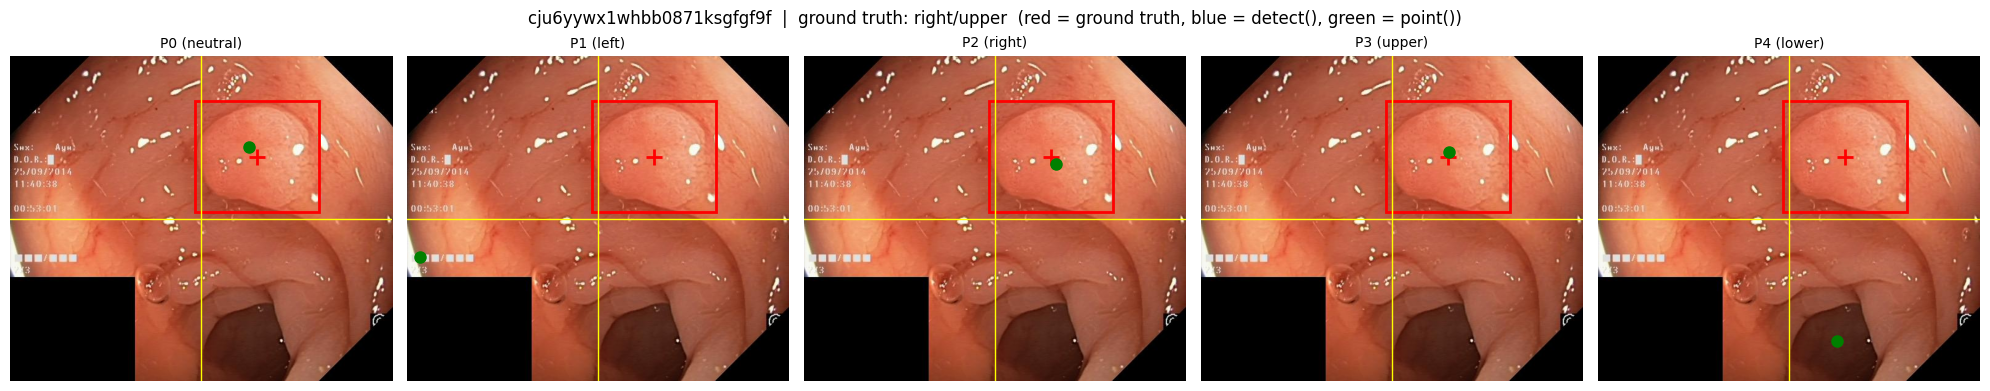

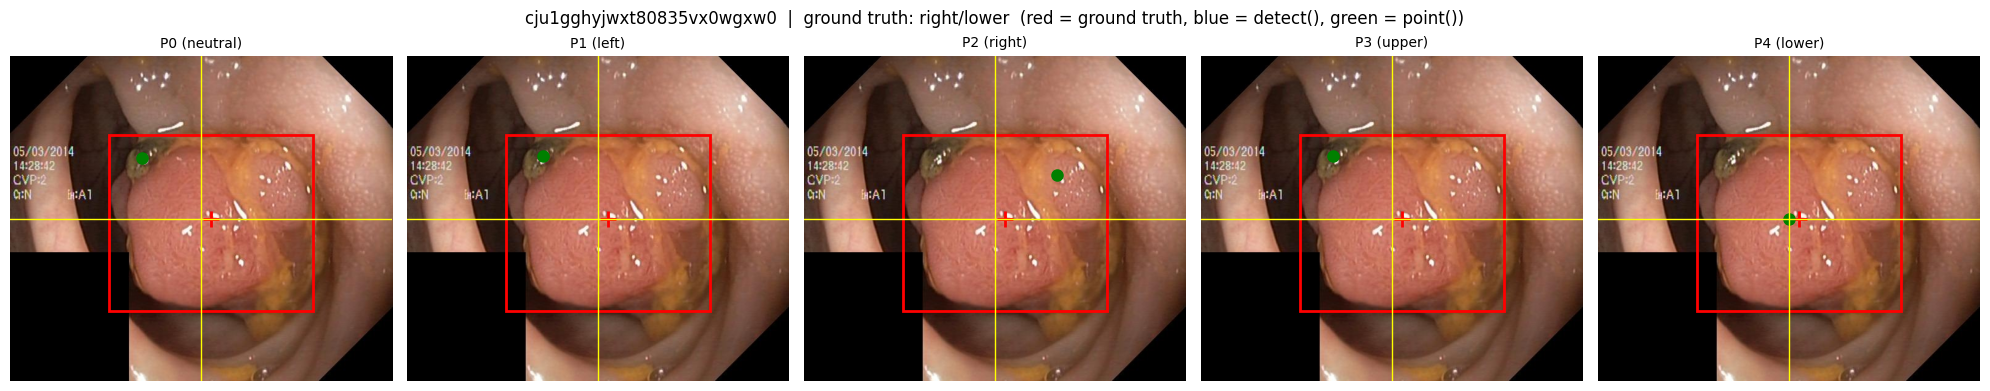

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_kvasir/visualizations
           md_detect_correct_side  md_point_correct_side  md_detect_no_shift  \
prompt_id                                                                      
P1                       0.857143                   0.96                 1.0   
P2                       1.000000                   1.00                 1.0   
P3                       0.600000                   0.88                 1.0   
P4                       1.000000                   0.94                 1.0   

           md_point_no_shift  md_detect_iou  md_detect_dist_norm  \
prompt_id                                                          
P1                      0.10       0.431492             0.138059   
P2                      0.40       0.471895             0.121598   
P3                      0.42       0.432207             0.119981   
P4                      0.32       0.769150             0.034476   

           md

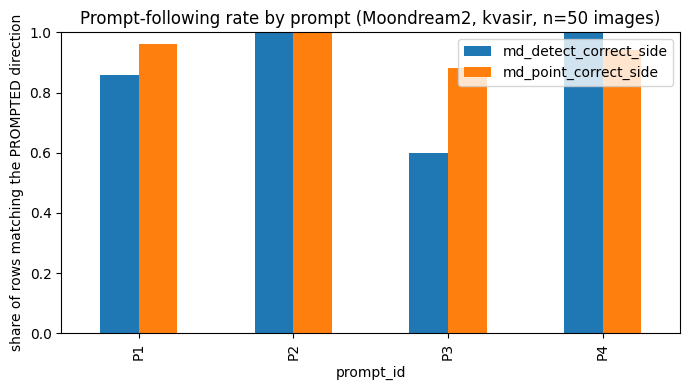

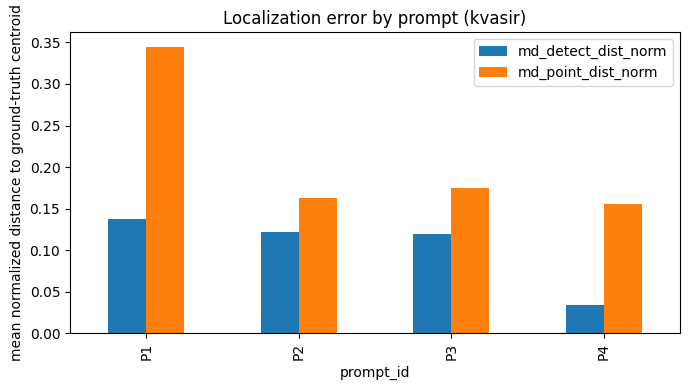

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_kvasir/kvasir_moondream2_summary_by_prompt.csv
RQ2 (kvasir) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           md_detect_correct_side  md_point_correct_side  md_detect_dist_norm  \
prompt_id                                                                       
P1                            1.0               1.000000             0.071228   
P2                            1.0               1.000000             0.081315   
P3                            0.5               0.961538             0.069328   
P4                            1.0               1.000000             0.005514   

           md_point_dist_norm  
prompt_id                      
P1                   0.204238  
P2                   0.102382  
P3                   0.095889  
P4                   0.096465  

RQ3 (kvasir) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over th

Moondream2 inference (isic):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows
[warn] 218 / 250 rows had a near-full-image detect() box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 44 columns -> /content/drive/MyDrive/run_colab/results_isic/isic_moondream2_results.csv


Rendering isic visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

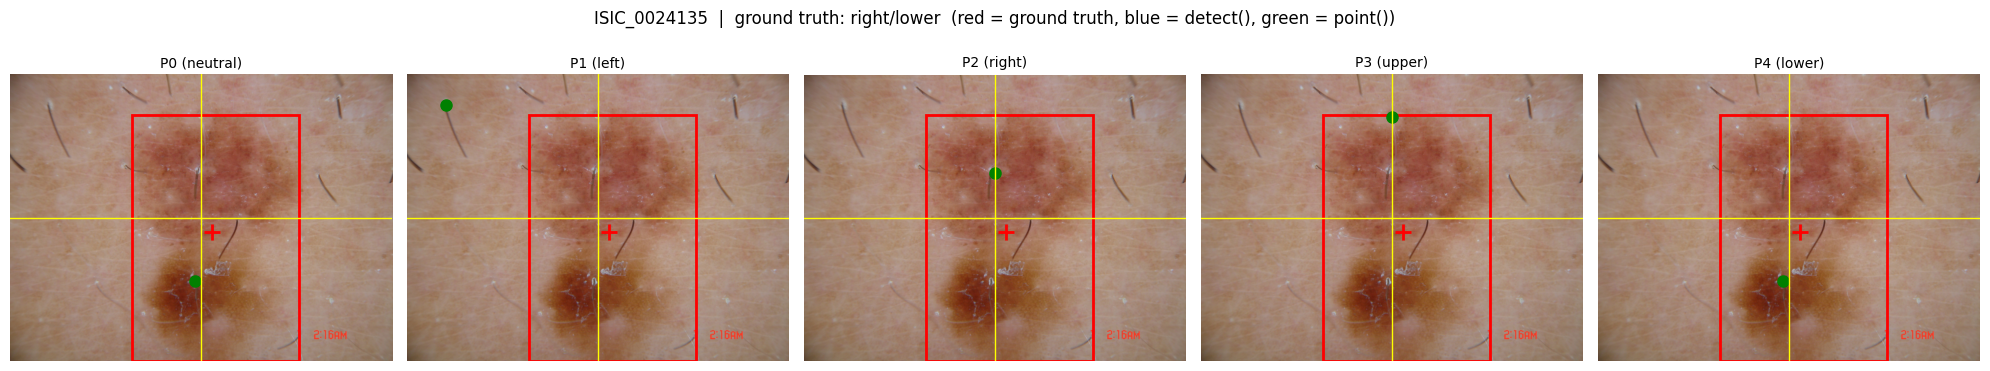

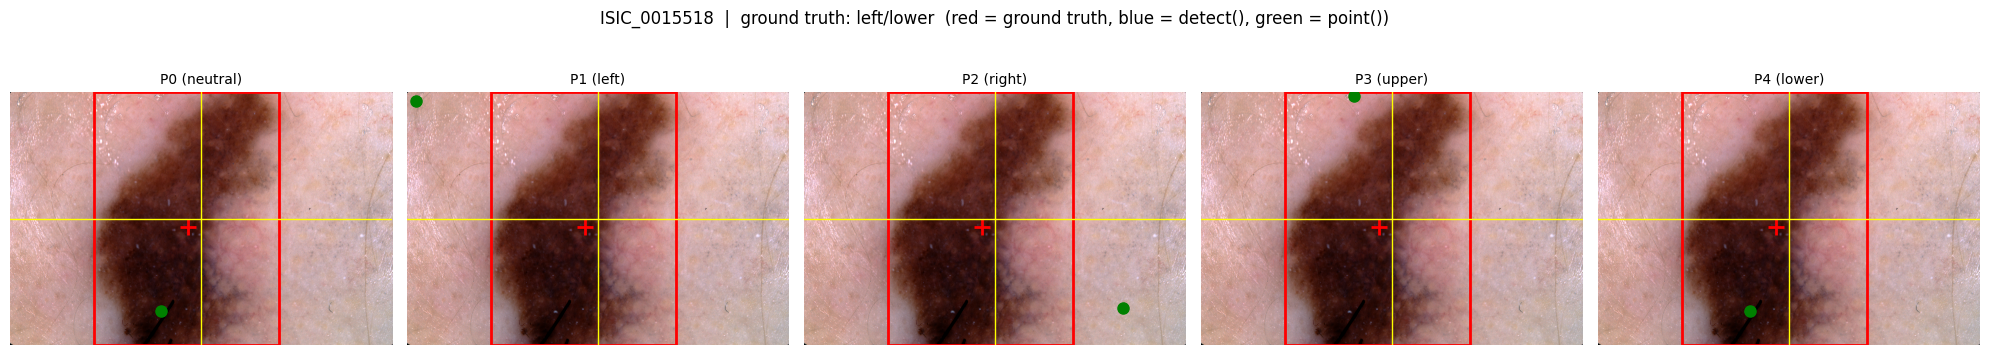

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_isic/visualizations
           md_detect_correct_side  md_point_correct_side  md_detect_no_shift  \
prompt_id                                                                      
P1                       0.875000                   0.98            0.666667   
P2                       1.000000                   1.00            1.000000   
P3                       0.666667                   0.68            1.000000   
P4                       0.666667                   1.00            1.000000   

           md_point_no_shift  md_detect_iou  md_detect_dist_norm  \
prompt_id                                                          
P1                      0.10       0.546189             0.129449   
P2                      0.16       0.901041             0.011187   
P3                      0.32       0.847707             0.010945   
P4                      0.48       0.898072             0.009317   

           md_p

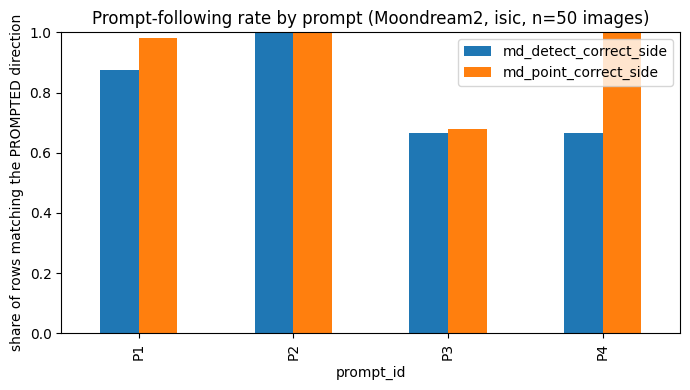

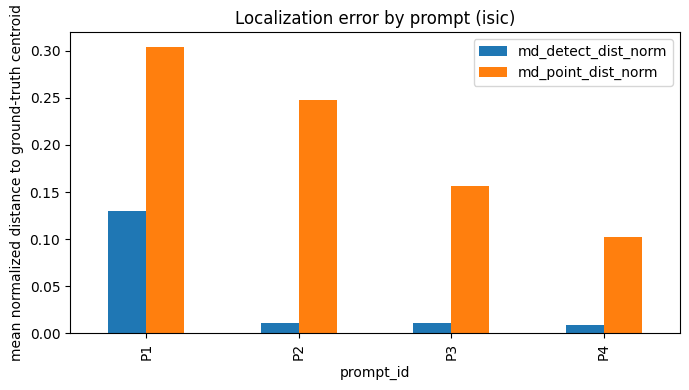

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_isic/isic_moondream2_summary_by_prompt.csv
RQ2 (isic) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           md_detect_correct_side  md_point_correct_side  md_detect_dist_norm  \
prompt_id                                                                       
P1                            1.0                    1.0             0.011706   
P2                            1.0                    1.0             0.011187   
P3                            1.0                    0.8             0.014677   
P4                            1.0                    1.0             0.007170   

           md_point_dist_norm  
prompt_id                      
P1                   0.262899  
P2                   0.210383  
P3                   0.159496  
P4                   0.100678  

RQ3 (isic) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels

Moondream2 inference (lgg):   0%|          | 0/250 [00:00<?, ?it/s]

[ok] ran inference on 250 rows
[warn] 8 / 250 rows had a near-full-image detect() box -> treated as no-detection
[ok] derived scoring columns computed
[ok] wrote 250 rows x 44 columns -> /content/drive/MyDrive/run_colab/results_lgg/lgg_moondream2_results.csv


Rendering lgg visualizations:   0%|          | 0/50 [00:00<?, ?it/s]

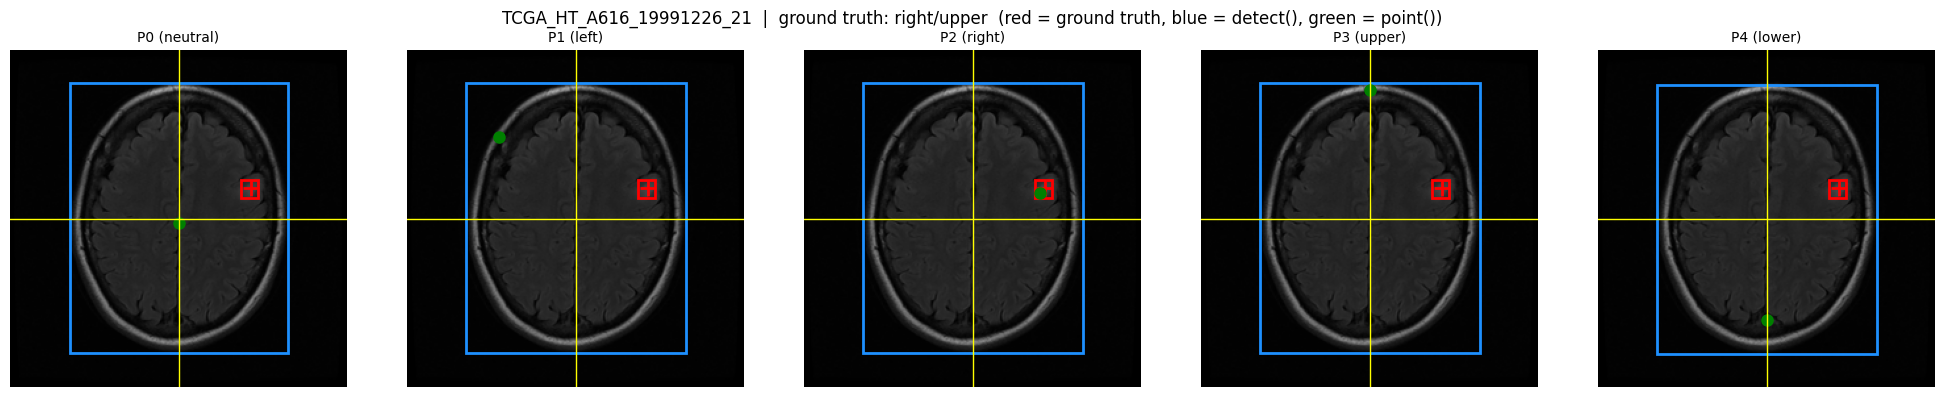

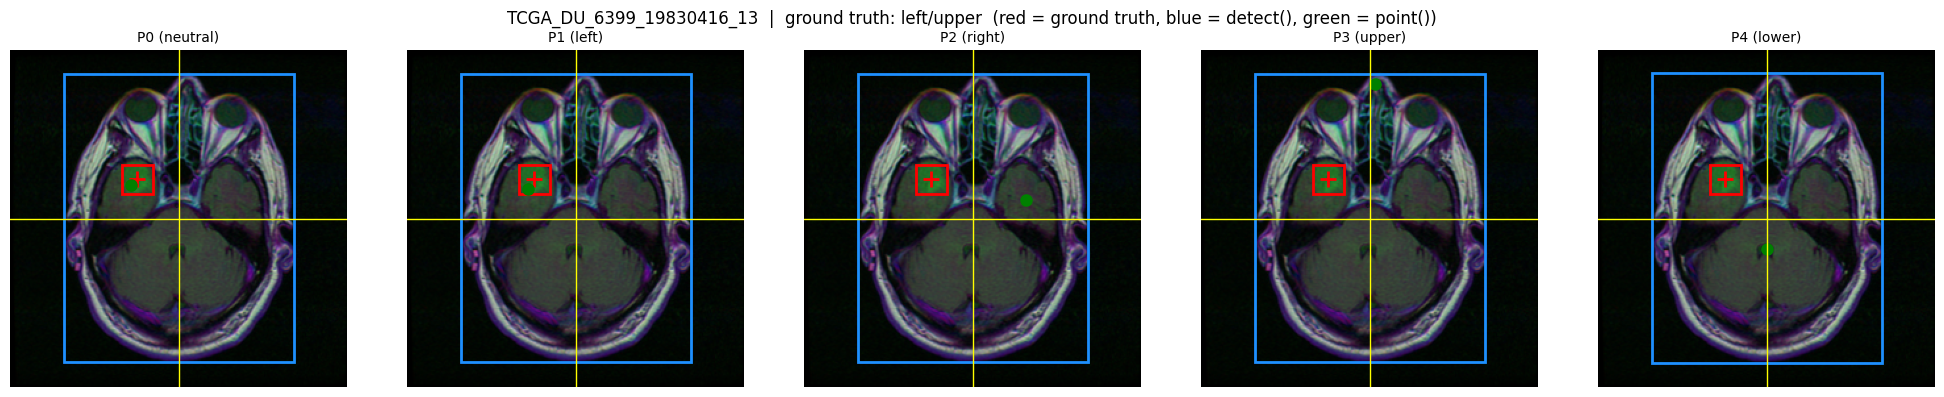

[ok] saved 50 comparison plots -> /content/drive/MyDrive/run_colab/results_lgg/visualizations
           md_detect_correct_side  md_point_correct_side  md_detect_no_shift  \
prompt_id                                                                      
P1                       0.244898                   0.78            0.795918   
P2                       0.957447                   1.00            0.872340   
P3                       0.346939                   0.92            0.938776   
P4                       0.765957                   0.98            0.851064   

           md_point_no_shift  md_detect_iou  md_detect_dist_norm  \
prompt_id                                                          
P1                      0.46       0.239421             0.091480   
P2                      0.44       0.195716             0.097908   
P3                      0.24       0.157235             0.102326   
P4                      0.26       0.120009             0.110722   

           md_po

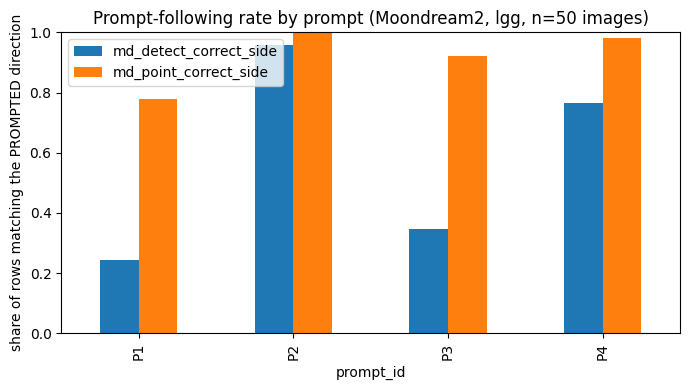

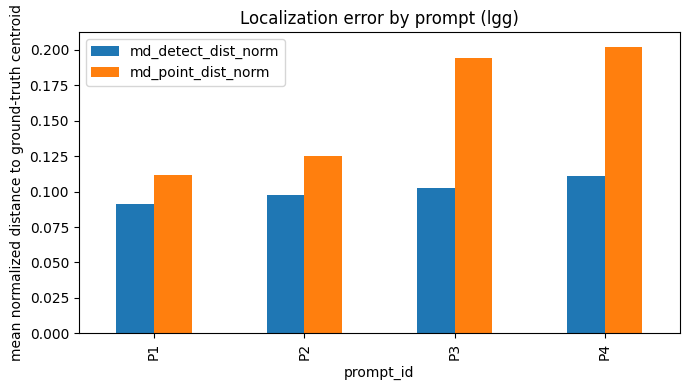

[ok] wrote summary -> /content/drive/MyDrive/run_colab/results_lgg/lgg_moondream2_summary_by_prompt.csv
RQ2 (lgg) -- prompt already matches ground truth (does wording alone still cause disagreement?):
           md_detect_correct_side  md_point_correct_side  md_detect_dist_norm  \
prompt_id                                                                       
P1                       0.500000               1.000000             0.072376   
P2                       1.000000               1.000000             0.083780   
P3                       0.393939               0.969697             0.097164   
P4                       0.800000               1.000000             0.120253   

           md_point_dist_norm  
prompt_id                      
P1                   0.062293  
P2                   0.060299  
P3                   0.154892  
P4                   0.150575  

RQ3 (lgg) -- prompt contradicts ground truth (a high correct_side rate here = model trusts the TEXT over the pixels):
 

In [16]:
ALL_DATASETS = ["kvasir", "isic", "lgg"]

all_dfs = {}
for dataset_name in ALL_DATASETS:
    print(f"\n{'=' * 80}\nProcessing dataset: {dataset_name}\n{'=' * 80}")
    data_dir, out_dir, vis_dir = get_dataset_paths(dataset_name, f"results_{dataset_name}")

    manifest_df = load_manifest(dataset_name, data_dir)
    result_df = run_moondream_inference(model, manifest_df, data_dir, desc=f"Moondream2 inference ({dataset_name})")
    result_df = score_predictions(result_df, data_dir)
    save_results(result_df, out_dir, dataset_name)
    render_visualizations(result_df, data_dir, vis_dir, dataset_name, show_first=2)
    aggregate_and_report(result_df, out_dir, dataset_name)
    report_rq2_rq3(result_df, dataset_name)

    all_dfs[dataset_name] = result_df

print("\n[ok] finished:", list(all_dfs.keys()))